In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
from PIL import Image

In [2]:
data = pd.read_csv("data.csv")
data = data[["condition", "delay", "efference_length", "seed",
             "actual_step", "reward_final", "steps_to_950"]]

In [3]:
data.condition.unique()

array(['fm_servo', 'fm_torque', 'mlp_servo', 'mlp_torque'], dtype=object)

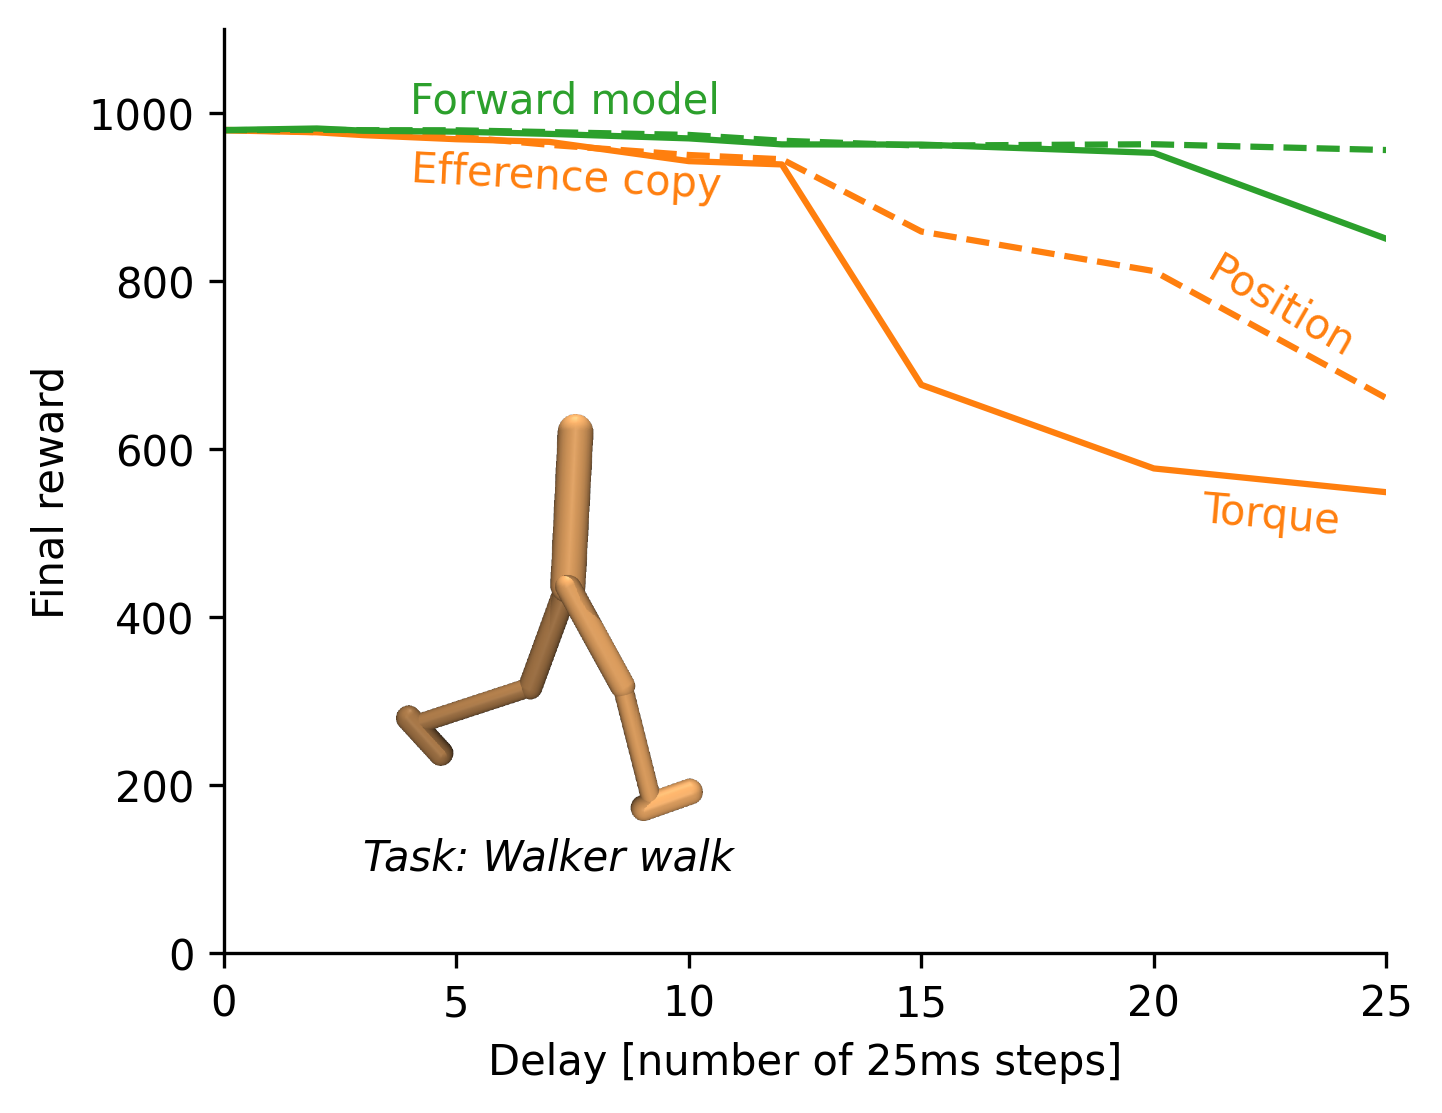

In [32]:
#fig, axs = plt.subplots(1, 2, figsize=(8, 4))
#sns.lineplot(data=data, x="delay", y="reward_final", hue="condition")
plt.figure(figsize=(5, 4), dpi=300)
g = data.groupby(["condition", "delay"])[["reward_final", "steps_to_950"]]
plt.plot(g.mean().loc["mlp_torque"].reward_final, color="C1")
plt.plot(g.mean().loc["mlp_servo"].reward_final, color="C1", linestyle="--")

plt.plot(g.mean().loc["fm_torque"].reward_final, color="C2")
plt.plot(g.mean().loc["fm_servo"].reward_final, color="C2", linestyle="--")

plt.ylim(0, 1100)
plt.xlim(0, 25)
plt.xlabel("Delay [number of 25ms steps]")
plt.ylabel("Final reward")
plt.text(21, 500, "Torque", color="C1", rotation=-5)
plt.text(21, 710, "Position", color="C1", rotation=-30)
plt.text(4, 900, "Efference copy", color="C1", rotation=-3)
plt.text(4, 1000, "Forward model", color="C2", rotation=0)

im = Image.open(f"../three-arm-overview/illustrations/walker.png")
im = matplotlib.offsetbox.OffsetImage(im, zoom=0.15)
plt.gca().add_artist(matplotlib.offsetbox.AnnotationBbox(im, (7, 400), frameon=False))
plt.text(3, 100, "Task: Walker walk", style="italic")
sns.despine()